In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('../')
sys.path.append('../hovernet')
sys.path.append('../hedest')

import json
import os
import pickle
import torch
import scanpy as sc
import pandas as pd
import seaborn as sns
sns.set_context("talk")
sns.set_style("whitegrid")

PATH = '/home/luca/Documents/data/'

# Load data

To use the analysis tools, you need to give several inputs : model info, image, adata and segmentation. In order to perform all possible analysis, we load everything that can be useful (spot proportions, single-cell images...) :

In [2]:
from hedest.utils import load_spatial_adata

#load adata
adata_name = 'Visium_FFPE_Human_Breast_Cancer'
data_path = os.path.join(PATH, adata_name)
path_ST_adata = os.path.join(data_path, "adata.h5ad")
adata = load_spatial_adata(path_ST_adata)

#load segmentation
json_path = os.path.join(data_path, "seg_json/pannuke_fast_mask_lvl3.json")
with open(json_path) as json_file:
    hovernet_dict = json.load(json_file)

#load spot proportions
spot_prop_df = pd.read_csv('DestVI_BRCA_prop.csv', index_col=0)
spot_prop_df.index = spot_prop_df.index.astype(str)
ct_list = spot_prop_df.columns.tolist()

/home/luca/anaconda3/envs/plugin-env/lib/python3.9/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [3]:
#load images
image_path = os.path.join(data_path, "pyr_tif/Visium_FFPE_Human_Breast_Cancer_image.tif")
image_dict = torch.load(os.path.join(data_path, "image_dict_64px_20um.pt"))

In [ ]:
#load model infos
model_dir = '../models/BRCA/DestVI_4000_hvg_squash_06_02/model_default_hidden_dim_512-256_norm_True_dropout_0.0_alpha_0.0_lr_0.0001_divergence_l2_beta_0.0_seed_3'

with open(os.path.join(model_dir, 'info.pickle'), 'rb') as f:
    model_info = pickle.load(f)

We then build the analyzer object :

In [5]:
from hedest.analysis.pred_analyzer import PredAnalyzer

analyzer = PredAnalyzer(model_info=model_info)

Loading predicted labels...
Use `add_attributes(seg_dict=your_seg_dict)` to add one.


In [6]:
analyzer.add_attributes(image_dict=image_dict,
                        adata=adata,
                        adata_name=adata_name,
                        image_path=image_path,
                        seg_dict=hovernet_dict)

# Deconvolution analysis

Before looking at the HEDeST predictions, let's have a look at some basic plots we can make directly from deconvolution results. The first plot is a co-localization matrix. Correlation between cell types A and B is equal to the Pearson Correlation between the proportion vector of A and the proportion vector of B :

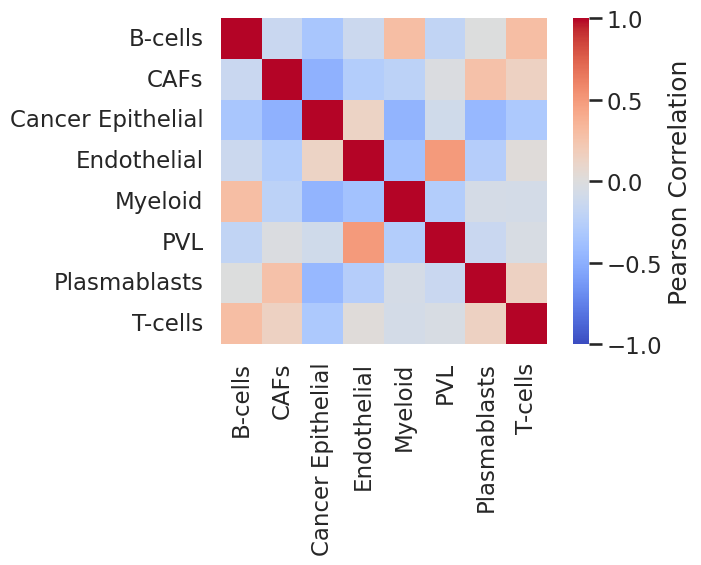

In [ ]:
analyzer.plot_colocalization_matrix(display=False)
# fig.savefig(f'figures/coloc_matrix.svg', format='svg', dpi=300, bbox_inches='tight')

We can also plot the predicted proportions directly on the histological slide. We first need to define a color_dict (or generate it with the function ```hedest.utils.generate_color_dict```) :

In [26]:
from hedest.analysis.postseg import StdVisualizer

color_dict = {
    '0': ['B-cells', [200, 255, 200, 255]],
    '1': ['CAFs', [255, 140, 0, 255]],
    '2': ['Cancer Epithelial', [31, 119, 180, 255]],
    '3': ['Endothelial', [230, 90, 60, 255]],
    '4': ['Myeloid', [0, 170, 140, 255]],
    '5': ['PVL', [255, 220, 100, 255]],
    '6': ['Plasmablasts', [128, 0, 128, 255]],
    '7': ['T-cells', [0, 150, 0, 255]]
}

analyzer.color_dict = color_dict
plotter = StdVisualizer(image_path, 
                        adata, 
                        adata_name, 
                        seg_dict=analyzer.seg_dict_w_class,
                        color_dict=color_dict)

Visium data found.


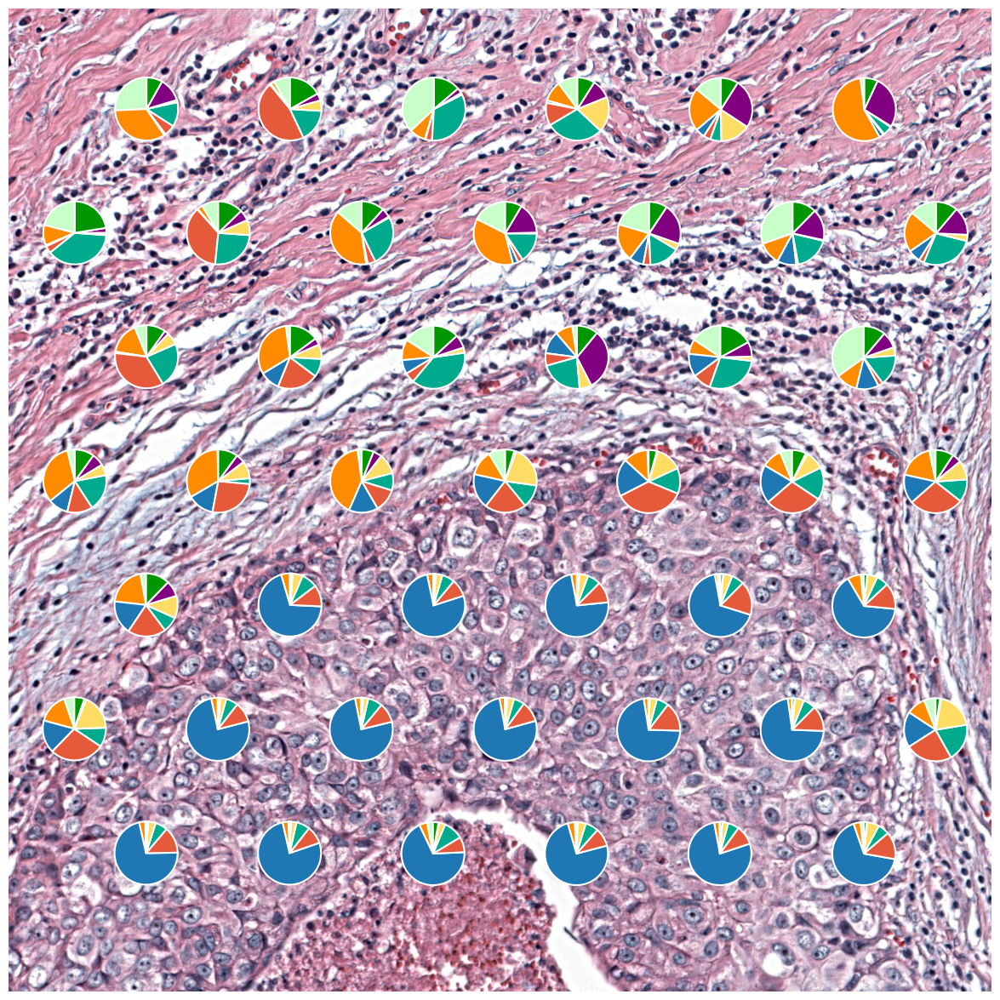

In [ ]:
window = ((9500, 10500), (2000, 2000))
plotter.plot_slide(window, title="", spot_prop_df=spot_prop_df, show_visium=True, display=False)
# fig.savefig(f'figures/big_crop_props.svg', format='svg', dpi=300, bbox_inches='tight')

# HEDeST predictions

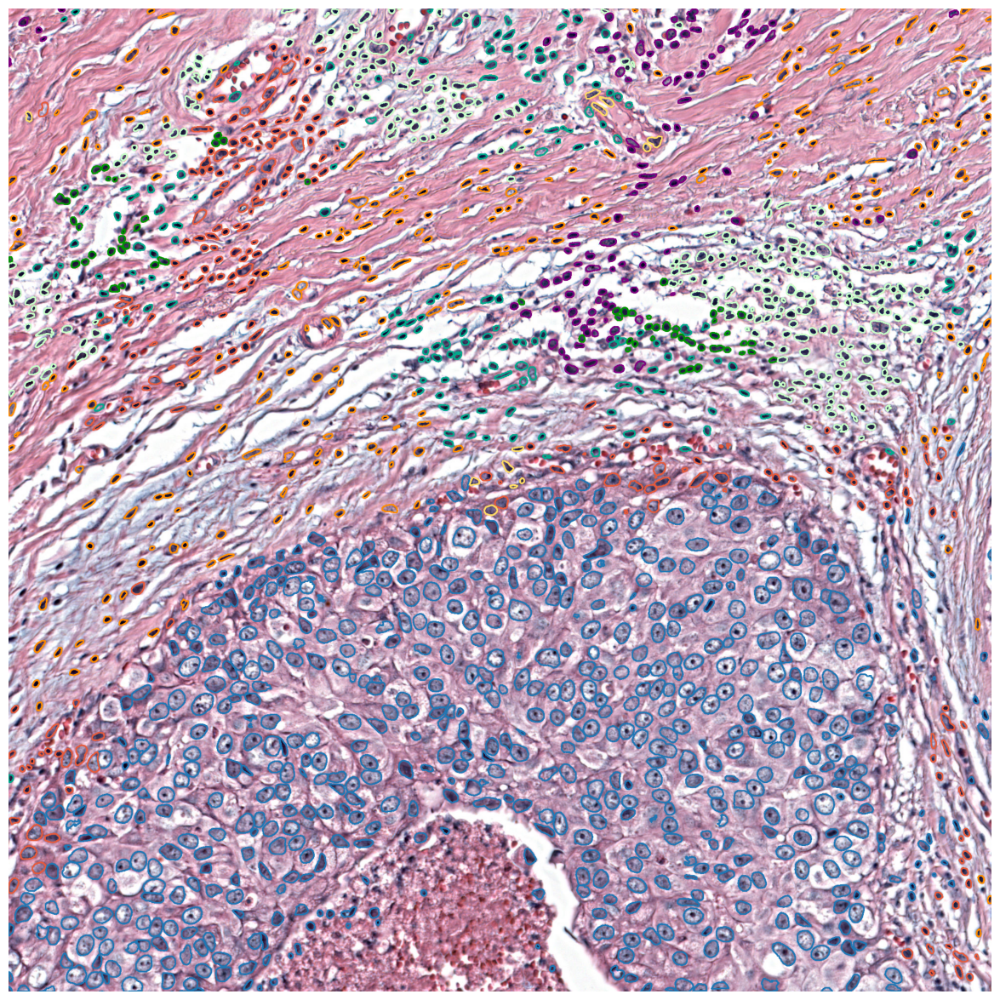

In [ ]:
window = ((9500, 10500), (2000, 2000))
plotter.plot_seg(window, title="", show_visium=False, display=False)
# fig.savefig(f'figures/big_crop_HEDeST.svg', format='svg', dpi=300, bbox_inches='tight')

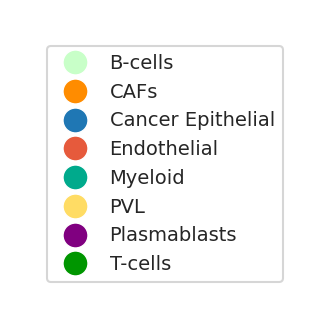

In [16]:
from hedest.analysis.plots import plot_legend

plot_legend(color_dict)

# Prediction analysis

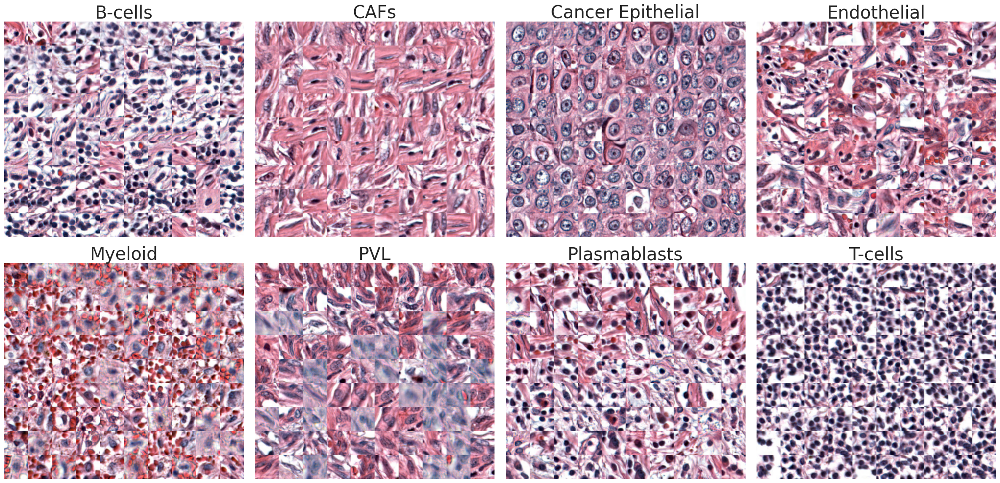

In [ ]:
analyzer.plot_grid_celltype(n=90, selection="max", show_probs = False, display=False, nrows=2, ncols=4, fontsize=30)
# fig.savefig(f'figures/grid_celltype.svg', format='svg', dpi=300, bbox_inches='tight')

B-cells > T-cells: U=562701.500, p=9.3062e-07 (***)
Plasmablasts > B-cells: U=2083140.000, p=2.1712e-07 (***)


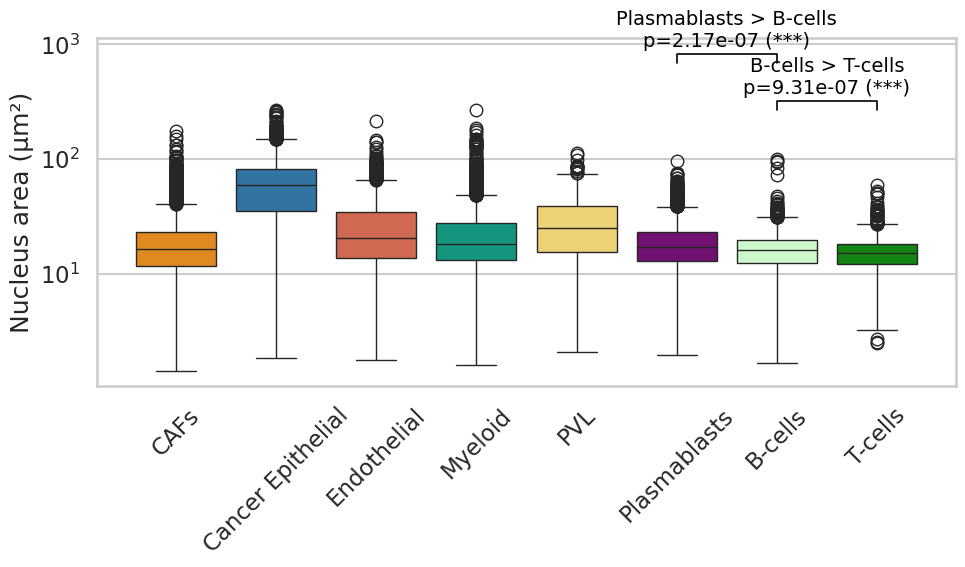

In [ ]:
new_ct_list = ['CAFs', 'Cancer Epithelial', 'Endothelial', 'Myeloid', 'PVL', 'Plasmablasts', 'B-cells', 'T-cells']
analyzer.compare_area(cell_types=new_ct_list,
                      ct_utest=[['B-cells', 'T-cells'], ['Plasmablasts', 'B-cells']],
                      height_unit_factor=0.18,
                      y_offset_factor=1.2,
                      fontsize_utest=14,
                    #   savefig='figures/area_comparison.svg'
                      )

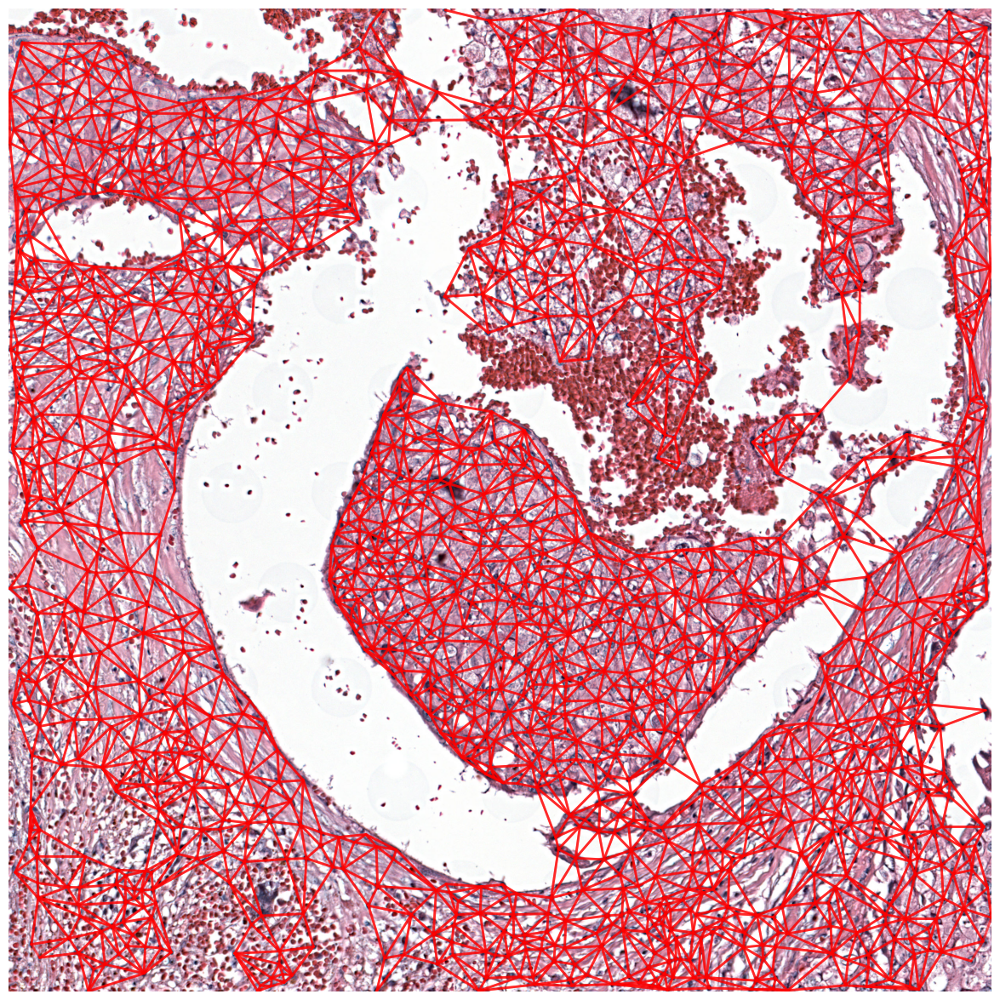

In [ ]:
plotter.plot_delaunay_graph(window=((18500, 12000), (2500, 2500)),
                            max_distance=150,
                            linewidth=2,
                            display = False
                            )
# fig.savefig(f'figures/delaunay_graph.pdf', dpi=300, bbox_inches='tight')

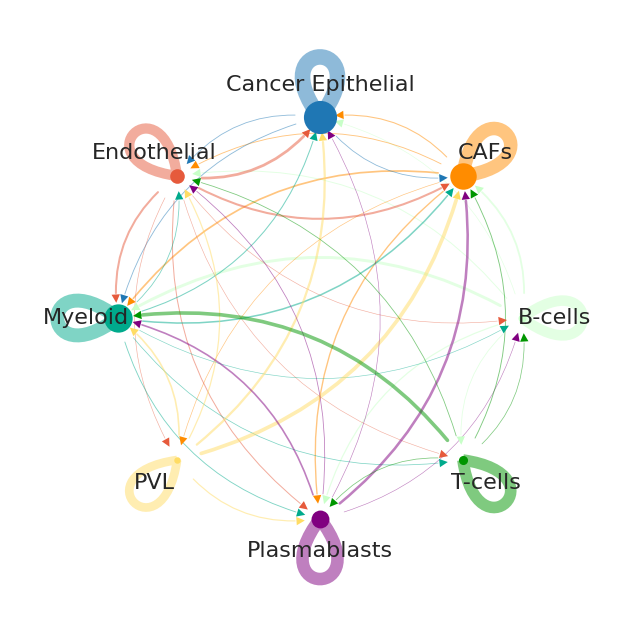

In [ ]:
analyzer.compute_neighborhood_composition(max_distance=None)
analyzer.plot_colocalization_graph(display=False, fontsize=16)
# fig.savefig(f'figures/coloc_graph.svg', format='svg', dpi=600, bbox_inches='tight')

This plot visualizes the neighborhood relationships between cell types. For each cell, we identify its immediate neighbors using the Delaunay graph. We then group cells by cell type. For a given cell type A, we calculate the average number of cells of each other cell type found in the neighborhood of cells belonging to type A.

The arrow from cell type A to cell type B has a thickness proportional to the average number of type B cells in the neighborhood of type A cells.

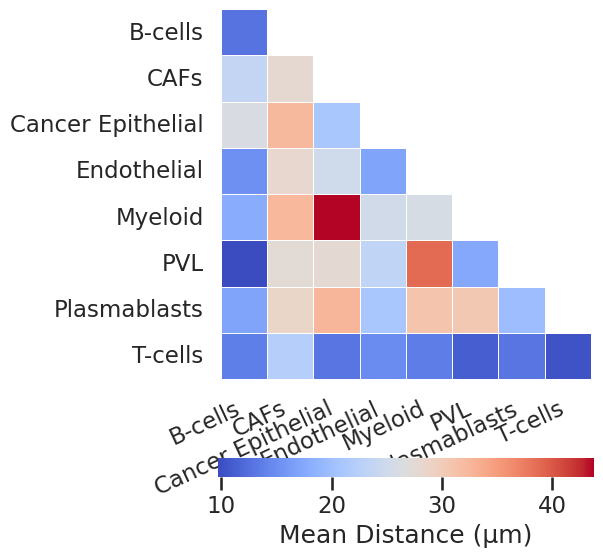

In [ ]:
analyzer.plot_mean_neighbor_distances(display=False)
# fig.savefig(f'figures/mean_neighbor_distances.svg', format='svg', dpi=600, bbox_inches='tight')

# Cluster analysis
## Spot-level clustering

In order to see if HEDeST brings new information to deconvolution, we first need to perform the clustering analysis on spot-level proportions.

In [35]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

# Gaussian mixture
from sklearn.mixture import GaussianMixture
lowest_bic = np.infty
best_gmm = None
n_components_range = range(2, 50)

df_props = spot_prop_df.copy()
df_props.columns = range(df_props.shape[1])

for n_components in n_components_range:
    gmm = GaussianMixture(n_components=n_components, covariance_type='full', random_state=42)
    gmm.fit(df_props.values)
    bic = gmm.bic(df_props.values)
    if bic < lowest_bic:
        lowest_bic = bic
        best_gmm = gmm

cluster_labels = best_gmm.predict(df_props.values)
n_clusters = best_gmm.n_components

# --- Compute centroids ---
cluster_series = pd.Series(cluster_labels, index=df_props.index, name="cluster")
df_with_clusters = df_props.join(cluster_series)
df_with_clusters = df_with_clusters[df_with_clusters["cluster"] != -1]
centroids = df_with_clusters.groupby("cluster").mean()

# --- Add to adata ---
adata.obs["gmm_clusters"] = cluster_series.astype(str)

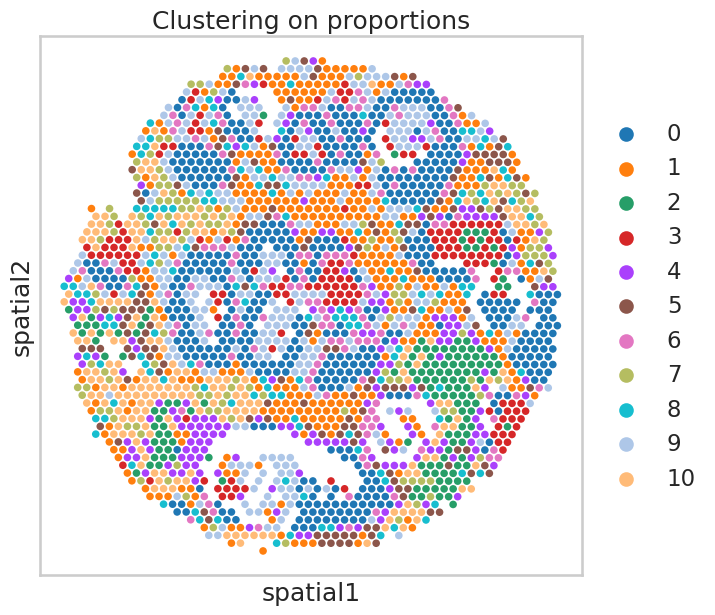

In [ ]:
from matplotlib import rcParams
FIGSIZE = (7, 7)
rcParams["figure.figsize"] = FIGSIZE

adata.obsm["spatial"][:, 0] = adata.obsm["spatial"][:, 0].astype(int)
adata.obsm["spatial"][:, 1] = -adata.obsm["spatial"][:, 1].astype(int)
g = sc.pl.embedding(adata, basis="spatial", color="gmm_clusters", s=120, title="Clustering on proportions", show=True, return_fig=True)
# g.savefig(f'figures/proportions_clusters.svg', format='svg', dpi=300, bbox_inches='tight')

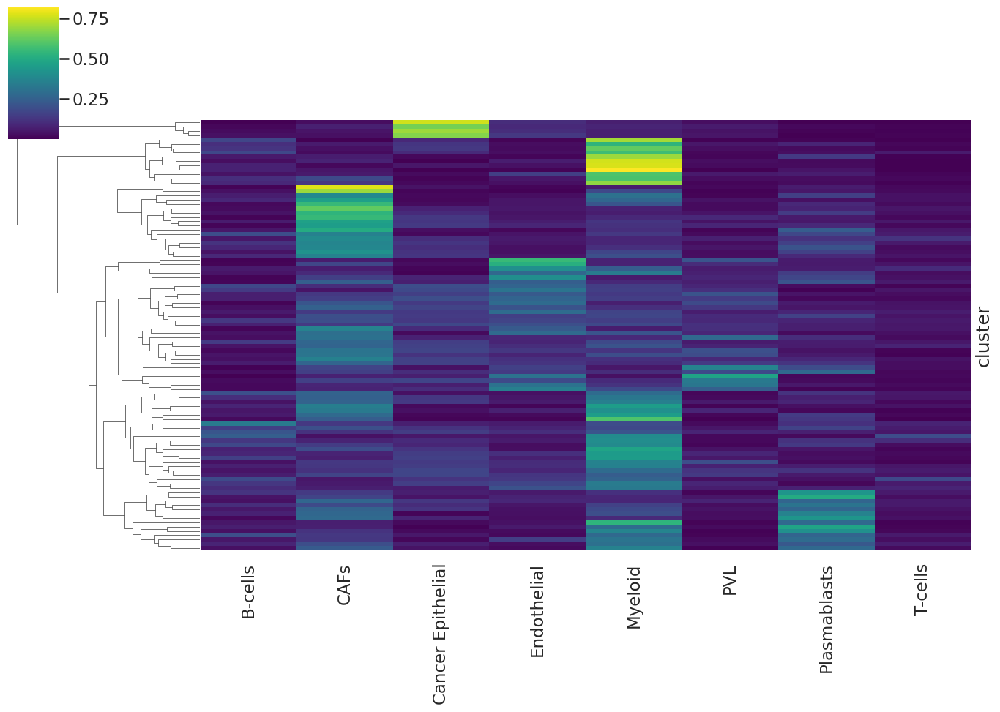

In [ ]:
import pandas as pd
import numpy as np
from sklearn.mixture import GaussianMixture
import seaborn as sns
import matplotlib.pyplot as plt

rename_dict = {int(k): v[0] for k, v in color_dict.items()}
df_props = df_props.rename(columns=rename_dict)

# --- Step 1: Gaussian Mixture clustering ---
n_clusters = 100
gmm = GaussianMixture(n_components=n_clusters, covariance_type='full', random_state=42)
cluster_labels = gmm.fit_predict(df_props.values)

# --- Step 2: attach cluster labels ---
cluster_series = pd.Series(cluster_labels, index=df_props.index, name="cluster")
df_with_clusters = df_props.join(cluster_series)

# --- Step 3: compute centroids (mean composition per cluster) ---
centroids = df_with_clusters.groupby("cluster").mean()

# --- Step 4: hierarchical clustering heatmap ---
sns.clustermap(
    centroids,
    method='average',
    metric='euclidean',
    cmap='viridis',
    figsize=(14, 10),
    xticklabels=True,   # show cell type names
    yticklabels=False,    # show cluster IDs
    col_cluster=False,
)
# plt.savefig('figures/neighborhood_clusters_heatmap.svg', format='svg', dpi=600, bbox_inches='tight')
plt.show()

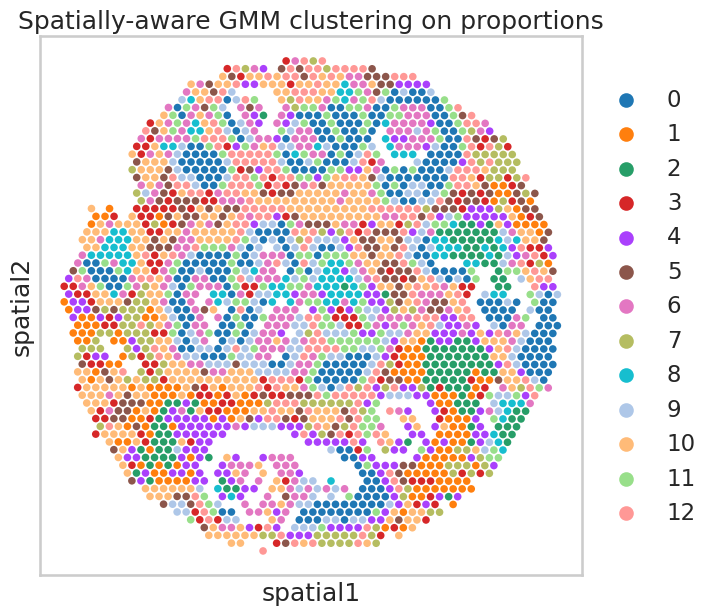

In [ ]:
import numpy as np
import pandas as pd
import scanpy as sc
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from matplotlib import rcParams
import matplotlib.pyplot as plt

seed = 42
np.random.seed(seed)

# -------------------------------
# Parameters
# -------------------------------
n_neighbors = 6      # number of spatial neighbors to consider
lambda_ = 0.5       # weight for neighbor contributions in spatial smoothing
n_components_range = range(2, 50)  # GMM component search

# -------------------------------
# Prepare data
# -------------------------------
df_props = spot_prop_df.copy()
df_props.columns = range(df_props.shape[1])  # ensure numeric columns

coords = adata.obsm['spatial']

# -------------------------------
# Build neighbor graph
# -------------------------------
nbrs = NearestNeighbors(n_neighbors=n_neighbors, algorithm='ball_tree').fit(coords)
distances, indices = nbrs.kneighbors(coords)

# -------------------------------
# Build adjacency matrix W
# -------------------------------
n_spots = df_props.shape[0]
W = np.zeros((n_spots, n_spots))
for i, neighbors in enumerate(indices):
    W[i, neighbors] = 1
# Row-normalize adjacency
W = W / W.sum(axis=1, keepdims=True)

# -------------------------------
# Compute spatially smoothed features
# -------------------------------
X = df_props.values
spatial_features = X + lambda_ * W @ X  # add neighbor influence

# -------------------------------
# GMM clustering
# -------------------------------
lowest_bic = np.infty
best_gmm = None

for n_components in n_components_range:
    gmm = GaussianMixture(n_components=n_components, covariance_type='full', random_state=42)
    gmm.fit(spatial_features)
    bic = gmm.bic(spatial_features)
    if bic < lowest_bic:
        lowest_bic = bic
        best_gmm = gmm

cluster_labels = best_gmm.predict(spatial_features)
adata.obs['spatial_gmm_clusters'] = pd.Series(cluster_labels, index=df_props.index).astype(str)

# -------------------------------
# Compute cluster centroids (optional)
# -------------------------------
cluster_series = pd.Series(cluster_labels, index=df_props.index, name="cluster")
df_with_clusters = df_props.join(cluster_series)
centroids = df_with_clusters.groupby("cluster").mean()

# -------------------------------
# Visualization
# -------------------------------
FIGSIZE = (7, 7)
rcParams["figure.figsize"] = FIGSIZE

# Flip y-axis if needed to match original spatial layout
# adata.obsm["spatial"][:, 0] = adata.obsm["spatial"][:, 0].astype(int)
# adata.obsm["spatial"][:, 1] = -adata.obsm["spatial"][:, 1].astype(int)

g = sc.pl.embedding(
    adata, 
    basis="spatial", 
    color="spatial_gmm_clusters", 
    s=120, 
    title="Spatially-aware GMM clustering on proportions", 
    show=True, 
    return_fig=True
)

# g.savefig(f'figures/spatial_proportions_clusters.svg', format='svg', dpi=300, bbox_inches='tight')

## Cell-level clustering

Here, we perform a clustering analysis to study neighborhood patterns. Starting from single-cell annotations, we “zoom out” to examine clusters defined by the composition of each cell’s local neighborhood. For every cell, we compute a vector representing the proportions of each cell type in its neighborhood. We then cluster the cells based on these proportion vectors.

In [59]:
import copy
import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

nuc_dict = copy.deepcopy(analyzer.seg_dict_w_class)
orig_types = {cid: cell_info.get("type", None) for cid, cell_info in analyzer.seg_dict_w_class["nuc"].items()}
neighbors = analyzer._build_delaunay_graph(max_distance=150)

unique_types = sorted(set(orig_types.values()))
type_to_idx = {t: i for i, t in enumerate(unique_types)}

# --- Build neighbor proportion vectors ---
rows = []
cell_ids = []

for cell_id in neighbors.keys():
    neigh_ids = neighbors.get(cell_id, [])
    neigh_types = [orig_types.get(nid) for nid in neigh_ids if nid in orig_types]

    if not neigh_types:
        continue

    counts = Counter(neigh_types)
    total = sum(counts.values())

    vec = np.zeros(len(unique_types))
    for t, c in counts.items():
        vec[type_to_idx[t]] = c / total

    rows.append(vec)
    cell_ids.append(cell_id)

df_props = pd.DataFrame(rows, index=cell_ids, columns=unique_types)

# --- Clustering ---

# HDBSCAN
# import hdbscan
# clusterer = hdbscan.HDBSCAN(min_cluster_size=400, metric='euclidean')
# cluster_labels = clusterer.fit_predict(df_props.values)
# n_clusters = len(set(cluster_labels)) - 1

# Gaussian mixture
from sklearn.mixture import GaussianMixture
lowest_bic = np.infty
best_gmm = None
n_components_range = range(2, 10)

for n_components in n_components_range:
    gmm = GaussianMixture(n_components=n_components, covariance_type='full', random_state=45)
    gmm.fit(df_props.values)
    bic = gmm.bic(df_props.values)
    if bic < lowest_bic:
        lowest_bic = bic
        best_gmm = gmm

cluster_labels = best_gmm.predict(df_props.values)

In [60]:
# --- Merge clusters ---
new_labels = cluster_labels.copy()
new_labels[cluster_labels == 6] = 4
cluster_labels = new_labels

n_clusters = len(np.unique(cluster_labels))

unique = sorted(np.unique(cluster_labels))
label_map = {old: new for new, old in enumerate(unique)}
cluster_labels = np.array([label_map[l] for l in cluster_labels])
n_clusters = len(unique)

In [61]:
# --- Compute centroids ---
cluster_series = pd.Series(cluster_labels, index=df_props.index, name="cluster")
df_with_clusters = df_props.join(cluster_series)
df_with_clusters = df_with_clusters[df_with_clusters["cluster"] != -1]
centroids = df_with_clusters.groupby("cluster").mean()

In [62]:
from itertools import chain

# --- Replace types with clusters ---
for cid, clabel in zip(df_props.index, cluster_labels):
    nuc_dict["nuc"][cid]["type"] = str(clabel)

for cid in nuc_dict["nuc"]:
    if cid not in df_props.index:
        nuc_dict["nuc"][cid]["type"] = str(-1)

# --- Color dictionary ---
cmap_list = [plt.get_cmap(name) for name in ["Dark2", "tab20b", "tab20c"]]
colors = list(chain.from_iterable([cmap.colors for cmap in cmap_list]))
n_colors = len(colors)
palette = [
    tuple(int(c * 255) for c in colors[i % n_colors][:3]) + (255,)
    for i in range(n_clusters)
]

# --- Custom color remapping ---
color_remap = {
    4: 5,
    5: 1,
    1: 3,
    3: 4
}

color_dict_neighbors = {}

for i in range(n_clusters):
    if i in color_remap:
        source_color_idx = color_remap[i]
    else:
        source_color_idx = i

    color_dict_neighbors[str(i)] = [str(i), palette[source_color_idx]]

color_dict_neighbors[str(-1)] = ["no_cluster", (200, 200, 200, 255)]

Visium data found.


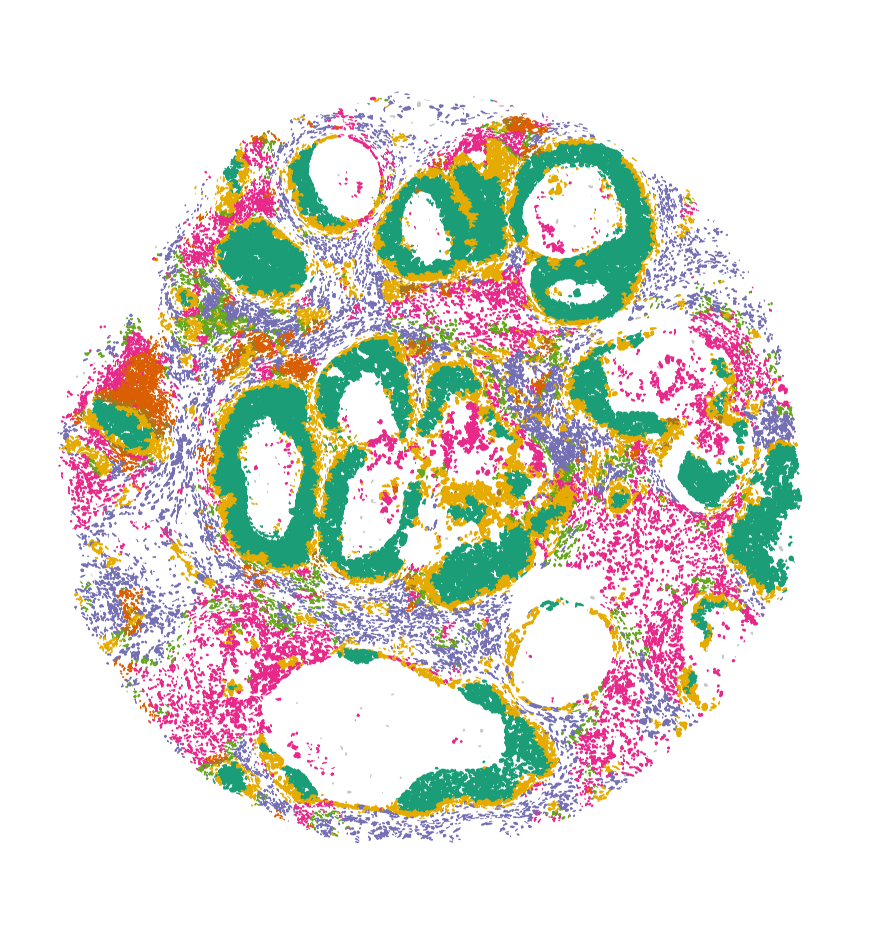

In [ ]:
plotter_neighbors = StdVisualizer(image_path, 
                        adata, 
                        adata_name, 
                        seg_dict=nuc_dict,
                        color_dict=color_dict_neighbors)

window = ((4900, 3400), (18800, 19900))
plotter_neighbors.plot_seg_overlays(window, separated=False, scale_cells=4, display = False)
# fig.savefig(f'figures/neighborhood_clusters.svg', dpi=600, format='svg', bbox_inches='tight')

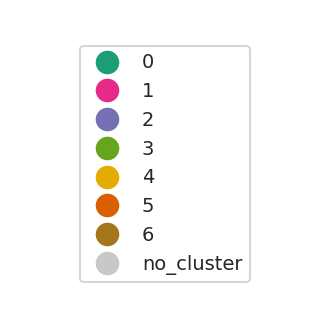

In [64]:
plot_legend(color_dict_neighbors)

([<matplotlib.patches.Wedge at 0x7e21bb5e13a0>,
 [Text(0.6542339348847781, 0.8842951760838573, ''),
  Text(0.833857561791682, -0.7174131073815361, ''),
  Text(-0.8704978914847503, -0.672483026492568, ''),
  Text(-0.9484927586316152, 0.5571009664534685, ''),
  Text(-0.4257317967535579, 1.0142743402221055, ''),
  Text(-0.09771934670505564, 1.0956509157936836, '')])

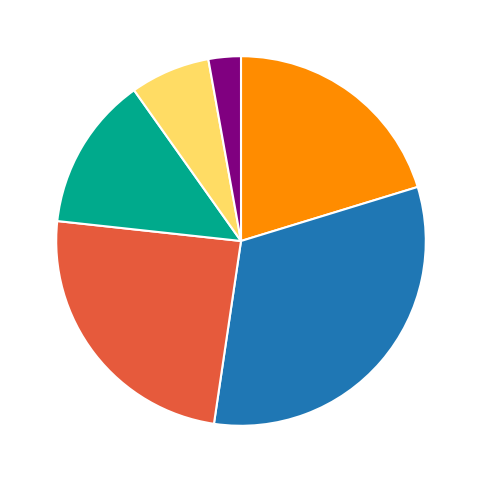

In [ ]:
cluster_id = 4

prop_centroid = centroids.loc[cluster_id]
prop_centroid = prop_centroid[prop_centroid > 0]
labels = [ct_list[i] for i in prop_centroid.index]

# Convert RGBA values to Matplotlib-friendly normalized RGB
colors = []
for idx in prop_centroid.index:
    rgba = color_dict[str(idx)][1]  # get RGBA from color_dict
    rgb_norm = [c/255 for c in rgba[:3]]  # ignore alpha for pie chart
    colors.append(rgb_norm)

plt.figure(figsize=(6, 6))
plt.pie(
    prop_centroid,
    colors=colors,    
    startangle=90,
    counterclock=False
)
# plt.savefig(f"figures/cluster_{cluster_id}_centroid.svg", format='svg', dpi=300, bbox_inches='tight')

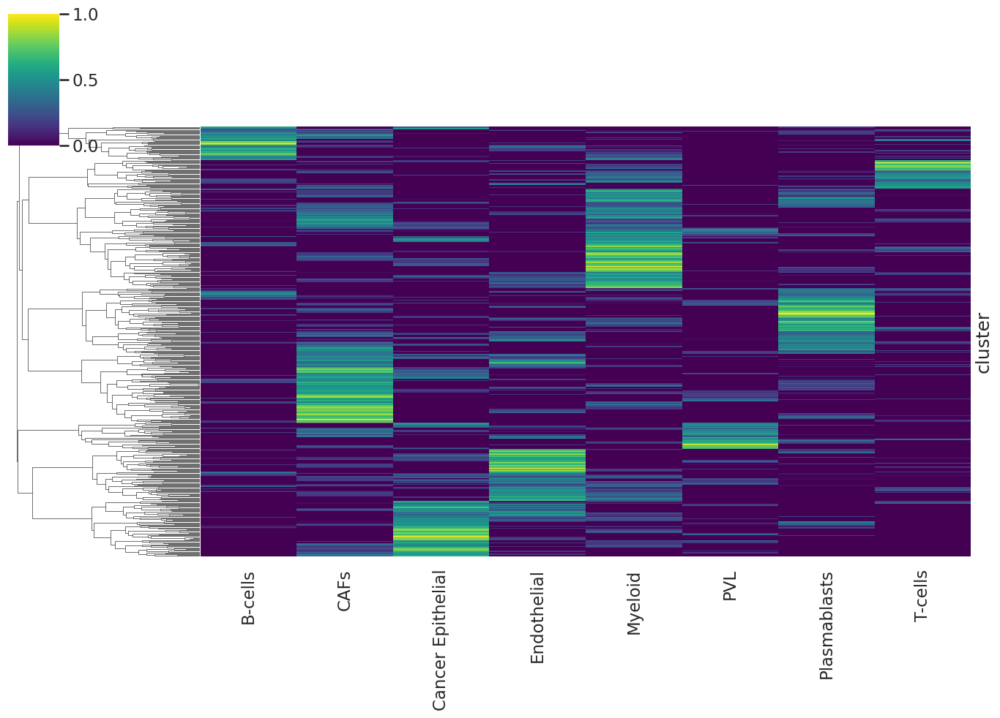

In [ ]:
import pandas as pd
import numpy as np
from sklearn.mixture import GaussianMixture
import seaborn as sns
import matplotlib.pyplot as plt

rename_dict = {int(k): v[0] for k, v in color_dict.items()}
df_props = df_props.rename(columns=rename_dict)

# --- Step 1: Gaussian Mixture clustering ---
n_clusters = 500
gmm = GaussianMixture(n_components=n_clusters, covariance_type='full', random_state=42)
cluster_labels = gmm.fit_predict(df_props.values)

# --- Step 2: attach cluster labels ---
cluster_series = pd.Series(cluster_labels, index=df_props.index, name="cluster")
df_with_clusters = df_props.join(cluster_series)

# --- Step 3: compute centroids (mean composition per cluster) ---
centroids = df_with_clusters.groupby("cluster").mean()

# --- Step 4: hierarchical clustering heatmap ---
sns.clustermap(
    centroids,
    method='average',
    metric='euclidean',
    cmap='viridis',
    figsize=(14, 10),
    xticklabels=True,   # show cell type names
    yticklabels=False,    # show cluster IDs
    col_cluster=False,
)
# plt.savefig('figures/neighborhood_cell_level_clusters_heatmap.svg', format='svg', dpi=600, bbox_inches='tight')
plt.show()